Este código foi criado para desenvolver um modelo de CNN para quantificar células sem estar marcada por fluorescência.

# Imports data structuring

In [1]:
#organização dos arquivos
import os
#salvar/carregar arquivos em diferentes formatos
import joblib
#organizando os arquivos de forma aleatória
import random
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#gerar imagem
import matplotlib.image as mpimg

# CNN template import

In [2]:
#modelo de revisão redes neurais - cnn
from keras.models import Sequential
from keras.utils import to_categorical # Import directly from keras.utils
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten

2026-10-18 13:47:10.052710: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 13:47:10.068516: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 13:47:10.194697: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 13:47:10.197717: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

Documents from different files will be stored in this directory

In [4]:
diretorio = "./data/imagens de fluorescencia/save/"
lista_dados = [i for i in os.listdir(diretorio) if i.endswith('.gz') and 'valid' not in i and '10-18' in i]
printLis(lista_dados) #printando as diferentes listas

-------------
-=< Lista >=-
-------------
0 -> lista_img_100_resized_fluorescente_cho745_2026-10-18.gz
1 -> lista_img_25_resized_fluorescente_cho745_2026-10-18.gz
2 -> lista_img_50_resized_fluorescente_cho745_2026-10-18.gz
3 -> lista_img_75_resized_fluorescente_cho745_2026-10-18.gz
4 -> lista_rotulo_100_resized_fluorescente_cho745_2026-10-18.gz
5 -> lista_rotulo_25_resized_fluorescente_cho745_2026-10-18.gz
6 -> lista_rotulo_50_resized_fluorescente_cho745_2026-10-18.gz
7 -> lista_rotulo_75_resized_fluorescente_cho745_2026-10-18.gz


## x = features/images

In [5]:
# #0 - 100% somando todas as imagens de diferentes tamanho
# X_cem = joblib.load(diretorio+ '/' + lista_dados[1])

# # 2 - 75%
# X_setcin = joblib.load(diretorio+ '/' + lista_dados[3])

# # 4 - 50%
# X_cinq = joblib.load(diretorio+ '/' + lista_dados[5])

# # 6 - 25%
# X_vincin = joblib.load(diretorio+ '/' + lista_dados[7])

# x = np.asarray(list(X_cem) + list(X_setcin) + list(X_cinq) + list(X_vincin))

# x.shape

In [6]:
X_cem = joblib.load(diretorio + lista_dados[0])
x = np.asarray(list(X_cem))
x.shape

(160, 250, 300, 3)

# y = labels

Opening the labels that were saved in the preparation of the images

In [7]:
# #1 - 100% somando todos os rótulos de diferentes tamanho
# y_cem = joblib.load(diretorio+ '/' + lista_dados[2])

# #3 - 75%
# y_setcin = joblib.load(diretorio+ '/' + lista_dados[4])

# #4 - 50%
# y_cinq = joblib.load(diretorio+ '/' + lista_dados[6])

# #7 - 25%
# y_vincin = joblib.load(diretorio+ '/' + lista_dados[0])

# y = np.asarray(list(y_cem) + list(y_setcin) + list(y_cinq) + list(y_vincin))

# y.shape

In [8]:
y_cem = joblib.load(diretorio + lista_dados[4])
y = np.asarray(list(y_cem))
y.shape

(160,)

#Separando dados de validação

In [9]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint
import numpy as np
import random
from sklearn.utils import resample
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error

In [10]:
from sklearn.utils import resample
from sklearn.metrics import accuracy_score  # Exemplo com acurácia

10% dos 624 - foram separados para validação do modelo.

In [11]:
zeros = list(np.zeros(144))
ones = list(np.ones(16))
lista = np.array(zeros + ones)
#lista

In [12]:
random.shuffle(lista) # Embaralhar aleatoriamente
lista_valida = [True if i == 1 else False for i in lista]
lista_treino_test = [False if i == 1 else True for i in lista]
#np.array(lista_valida)

In [13]:
#imagens
x_valida = x[lista_valida]
x_treino_test = x[lista_treino_test]

print(x_valida.shape)
print(x_treino_test.shape)

(16, 250, 300, 3)
(144, 250, 300, 3)


In [14]:
#rótulos
y_valida = y[lista_valida]
y_treino_test = y[lista_treino_test]

print(y_valida.shape)
print(y_treino_test.shape)

(16,)
(144,)


In [15]:
# Separar 10% das imagens para amostragem de reposição (Bootstrap)
num_amostragem = int(0.10 * len(x_treino_test))  # 10% do total
indices_amostragem = np.random.choice(len(x_treino_test), num_amostragem, replace=False)

x_amostragem_reposicao = x_treino_test[indices_amostragem]
y_amostragem_reposicao = y_treino_test[indices_amostragem]

In [16]:
# Remover essas imagens do conjunto principal
mascara_treino_test = np.ones(len(x_treino_test), dtype=bool)
mascara_treino_test[indices_amostragem] = False

x_treino_test = x_treino_test[mascara_treino_test]
y_treino_test = y_treino_test[mascara_treino_test]

print(f"Amostragem de Reposição: {x_amostragem_reposicao.shape}, {y_amostragem_reposicao.shape}")
print(f"Treino/Teste após remoção: {x_treino_test.shape}, {y_treino_test.shape}")

Amostragem de Reposição: (14, 250, 300, 3), (14,)
Treino/Teste após remoção: (130, 250, 300, 3), (130,)


Test and training separation from a library.

In [17]:
# Simulando 10 execuções do modelo com bootstrap
num_execucoes = 5
resultados = []


Para calcular a média dos resultados da quantificação em um experimento de AM, onde você realiza múltiplas execuções usando amostragem com reposição (bootstrap sampling)

Passo 1: Executar múltiplas iterações do modelo
Já que esta sendo usando amostragem com reposição, cada execução do modelo pode produzir resultados ligeiramente diferentes. Portanto, precisamos rodar o modelo várias vezes e armazenar os resultados.

Passo 2: Armazenar os valores da quantificação
Suponha que sua quantificação seja uma métrica como acurácia, número de células detectadas ou erro médio quadrático (MSE). Para cada iteração, salvamos esse valor.

Passo 3: Calcular a média e o desvio padrão
Após rodar o modelo várias vezes, podemos calcular a média e o desvio padrão dos resultados.

In [18]:
for i in range(num_execucoes):
    # Aplicar Bootstrap Sampling para treino - quem organiza a reposição
    #Criar diferentes subconjuntos de treino a partir do mesmo conjunto de dados original, permitindo estimar a variabilidade do modelo
    X_train, y_train = resample(x_treino_test, y_treino_test, replace=True, n_samples=len(x_treino_test), random_state=i)

    # Criar máscara para separar os dados de teste/ organiza o que vai ser separado pra treinamento e teste
    mascara_teste = np.ones(len(x_treino_test), dtype=bool)
    indices_treinados = np.array([np.where((x_treino_test == x).all(axis=(1,2,3)))[0][0] for x in X_train])
    mascara_teste[indices_treinados] = False

    X_test = x_treino_test[mascara_teste]
    y_test = y_treino_test[mascara_teste]

    # **Garantir que os dados são float32**
    X_train = np.array(X_train, dtype=np.float32)
    X_test = np.array(X_test, dtype=np.float32)
    y_train = np.array(y_train, dtype=np.float32)
    y_test = np.array(y_test, dtype=np.float32)

    # **Criar modelo**
    modelo = Sequential([
        Conv2D(32, kernel_size=3, activation='relu', input_shape=X_train.shape[1:]),
        MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'),
        Conv2D(64, kernel_size=3, activation='relu'),
        MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'),
        Conv2D(128, kernel_size=3, activation='relu'),
        MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'),
        Conv2D(256, kernel_size=3, activation='relu'),
        MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'),
        Flatten(),
        Dropout(0.9),
        Dense(1, activation='linear')
    ])

    # **Compilar modelo**
    modelo.compile(optimizer=Adam(), loss='mse', metrics=['mean_squared_error'])

    # **Early Stopping**
    es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=18)

    # **Treinar o modelo**
    history = modelo.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=200, verbose=0, callbacks=[es])

    # **Fazer previsões**
    y_pred = modelo.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)

    # **Armazenar resultado**
    resultados.append(mse)


Epoch 39: early stopping
2/2 [==============================] - 0s 104ms/step
Epoch 35: early stopping
2/2 [==============================] - 0s 142ms/step
Epoch 74: early stopping
2/2 [==============================] - 0s 116ms/step
Epoch 61: early stopping
2/2 [==============================] - 0s 132ms/step
Epoch 52: early stopping
2/2 [==============================] - 0s 132ms/step


In [24]:
# **Calcular estatísticas**
media_mse = np.mean(resultados)
desvio_padrao = np.std(resultados)

# **Exibir os resultados finais**
print(f"Média do erro quadrático médio (MSE): {media_mse:.4f}")
print(f"Desvio padrão do MSE: {desvio_padrao:.4f}")

Média do erro quadrático médio (MSE): 955.4544
Desvio padrão do MSE: 174.7718


In [25]:
resultados

[1019.619, 764.62366, 1028.3557, 752.73663, 1211.9369]

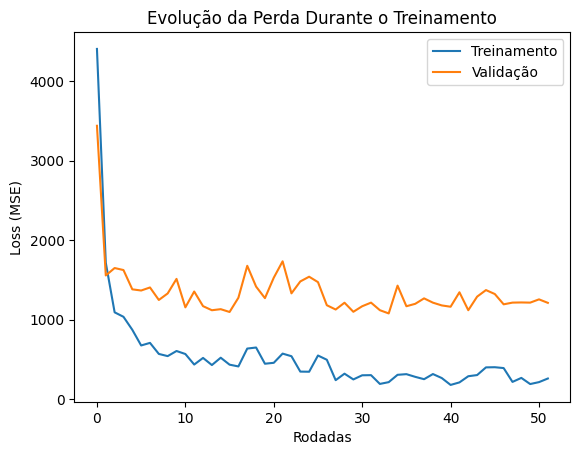

In [26]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Treinamento')
plt.plot(history.history['val_loss'], label='Validação')
plt.xlabel('Rodadas')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.title('Evolução da Perda Durante o Treinamento')
plt.show()

O modelo está aprendendo bem e reduzindo a perda nas primeiras rodadas.; Depois de algumas rodadas, ele estabiliza, indicando que atingiu um limite de aprendizado.

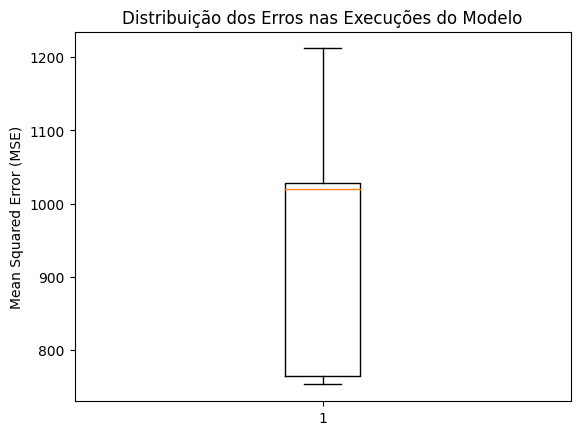

In [27]:
plt.boxplot(resultados)
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Distribuição dos Erros nas Execuções do Modelo')
plt.show()

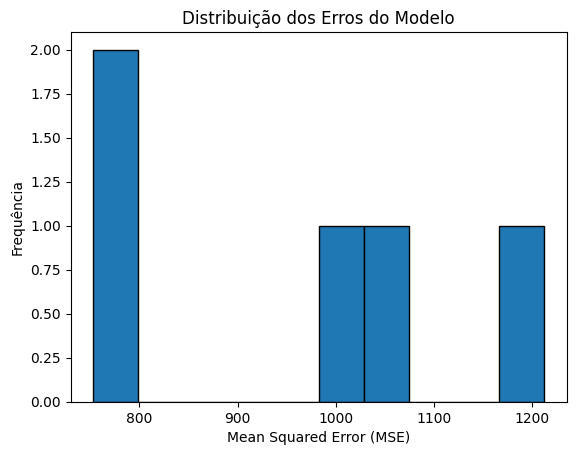

In [28]:
plt.hist(resultados, bins=10, edgecolor='black')
plt.xlabel('Mean Squared Error (MSE)')
plt.ylabel('Frequência')
plt.title('Distribuição dos Erros do Modelo')
plt.show()